In [32]:
import glob
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os
import shutil as sh

In [33]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [34]:
RUTA_BASE = "/content/drive/MyDrive/Tesis/vasijas"

CLASE = 4

RUTA_CLASIFICADOS = RUTA_BASE + "/Clasificados"
RUTA_MITADES = RUTA_BASE + "/Mitades"

perfiles = glob.glob(
    f'{RUTA_CLASIFICADOS}/Clase{CLASE:02d}/*.png'
)

vertical = CLASE in range(1, 10)

In [ ]:
def mostrar_imagen(imagen):
    plt.imshow(imagen, cmap=plt.cm.gray)
    plt.axis("on")
    plt.figure()


import numpy as np

def cortar_imagen_con_fondo(img, vertical):
    alto, ancho = img.shape

    # Crear fondos blancos
    borde  = np.full_like(img, 255)
    base  = np.full_like(img, 255)

    if vertical:
        mitad = alto // 2
        borde[:mitad] = img[:mitad]
        base[mitad:] = img[mitad:]
    else:
        mitad = ancho // 2
        borde[:, :mitad] = img[:, :mitad]
        base[:, mitad:] = img[:, mitad:]

    return borde, base


def guardar_mitad_imagen(
    ruta_imagen_original: str,
    imagen_mitad,
    sufijo: str,
    clase: int,
    ruta_mitades: str
):
    """
    Guarda una mitad de imagen en la carpeta correspondiente a su clase.

    Ejemplo de salida:
    RUTA_MITADES/Clase11/AL_03A_tope.png
    """

    # 1. Nombre del archivo sin extensión
    nombre_archivo = os.path.splitext(
        os.path.basename(ruta_imagen_original)
    )[0]

    # 2. Carpeta de la clase (Clase01, Clase11, etc.)
    carpeta_clase = f"Clase{clase:02d}"
    ruta_clase = os.path.join(ruta_mitades, carpeta_clase)

    # 3. Crear carpeta si no existe
    os.makedirs(ruta_clase, exist_ok=True)

    # 4. Ruta final del archivo
    ruta_salida = os.path.join(
        ruta_clase,
        f"{nombre_archivo}{sufijo}.png"
    )

    # 5. Guardar imagen
    cv2.imwrite(ruta_salida, imagen_mitad)

    return ruta_salida

def leer_imagen(ruta_imagen: str):
    img = cv2.imread(ruta_imagen, cv2.IMREAD_GRAYSCALE)
    return img

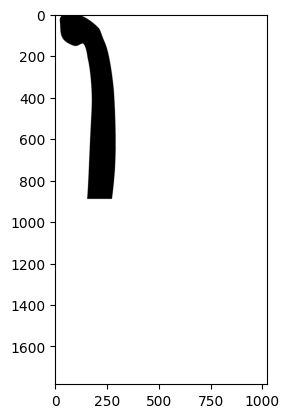

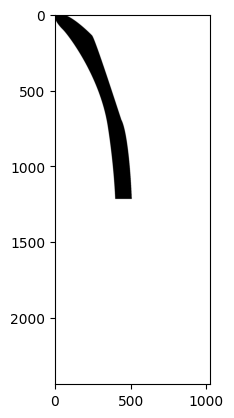

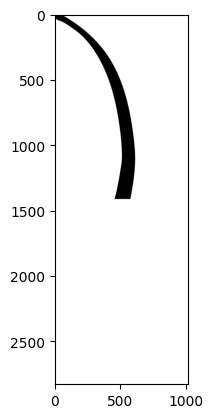

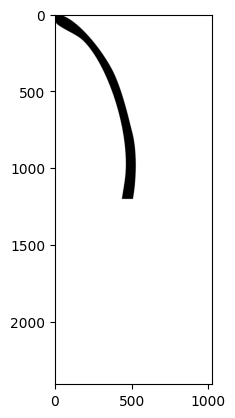

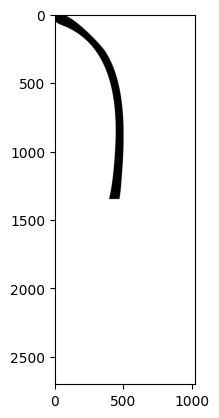

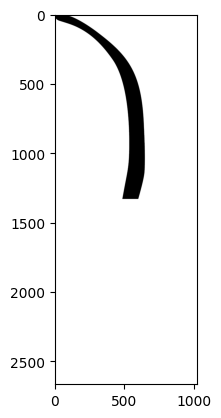

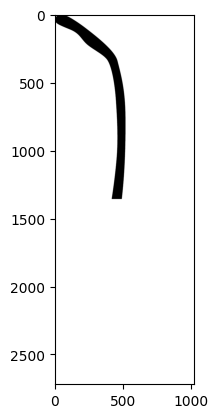

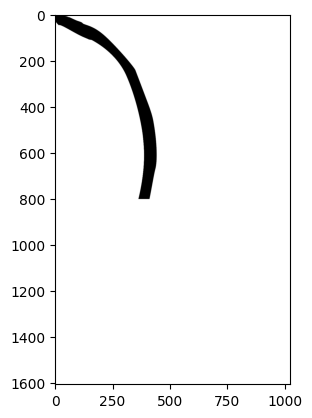

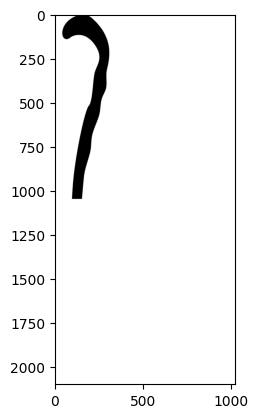

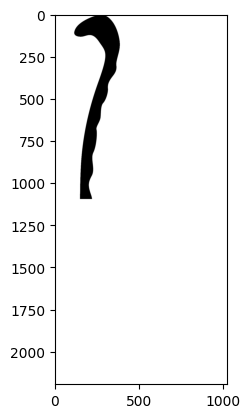

<Figure size 640x480 with 0 Axes>

In [36]:
# Crear carpeta base de mitades si no existe
os.makedirs(RUTA_MITADES, exist_ok=True)

for ruta_imagen in perfiles:

    img = leer_imagen (ruta_imagen)

    tope, base = cortar_imagen(img, vertical)

    mostrar_imagen(tope)
    # mostrar_imagen(base)

    # guardar_mitad_imagen(
    #     ruta_imagen_original = ruta_imagen,
    #     imagen_mitad = tope,
    #     sufijo = "_tope",
    #     clase = CLASE,
    #     ruta_mitades = RUTA_MITADES
    # )

    # guardar_mitad_imagen(
    #     ruta_imagen_original = ruta_imagen,
    #     imagen_mitad = base,
    #     sufijo = "_base",
    #     clase = CLASE,
    #     ruta_mitades = RUTA_MITADES
    # )